In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv('../datasets/dataset_clean.csv')
print("Setup ready!")

Setup ready!


In [2]:
# 1. Variasi Gaji berdasarkan Posisi Pekerjaan
gaji_posisi = df.groupby('posisi_pekerjaan_clean')['gaji_pokok_bulanan_idr'].agg(
    gaji_min='min',
    gaji_median='median',
    gaji_mean='mean',
    gaji_max='max'
).sort_values(by='gaji_median', ascending=False)

print("=== Ringkasan Gaji Bulanan per Posisi ===")
display(gaji_posisi)

# 2. Variasi Gaji berdasarkan Skala Perusahaan
gaji_skala = df.groupby('skala_perusahaan')['gaji_pokok_bulanan_idr'].agg(
    ['count', 'min', 'median', 'mean', 'max']
).sort_values(by='median', ascending=False)

print("\n=== Ringkasan Gaji Bulanan per Skala Perusahaan ===")
display(gaji_skala)

=== Ringkasan Gaji Bulanan per Posisi ===


,gaji_min,gaji_median,gaji_mean,gaji_max
posisi_pekerjaan_clean,,,,
Data Scientist,5500000,27500000.0,3.594507e+07,110000000
DevOps / SRE,5500000,27500000.0,3.502864e+07,110000000
Backend Engineer,6000000,27250000.0,3.473810e+07,110000000
Technical Writer,5500000,27000000.0,3.378137e+07,110000000
Machine Learning / AI Engineer,6000000,26500000.0,3.414922e+07,110000000
Cybersecurity Specialist,6000000,26500000.0,3.370300e+07,110000000
Fullstack Engineer,5500000,26000000.0,3.385886e+07,110000000
Frontend Engineer,5500000,26000000.0,3.413757e+07,110000000
QA / Test Engineer,5500000,26000000.0,3.387874e+07,110000000



=== Ringkasan Gaji Bulanan per Skala Perusahaan ===


,count,min,median,mean,max
skala_perusahaan,,,,,
Perusahaan Remote Global / Luar Negeri,493,9500000,36500000.0,4.639655e+07,110000000
Perusahaan FinTech / Bank Digital,1787,7500000,30000000.0,3.794180e+07,110000000
Decacorn / Unicorn Lokal,2262,7000000,29000000.0,3.732206e+07,110000000
Startup Growth Series B/C,2377,6500000,25500000.0,3.214472e+07,110000000
BUMN Teknologi / Telekomunikasi,782,6500000,23500000.0,3.076982e+07,110000000
Startup Early-Stage Seed/Pre-A,1595,5500000,22000000.0,2.865047e+07,110000000
Software House / IT Agency,704,5500000,21000000.0,2.724645e+07,110000000


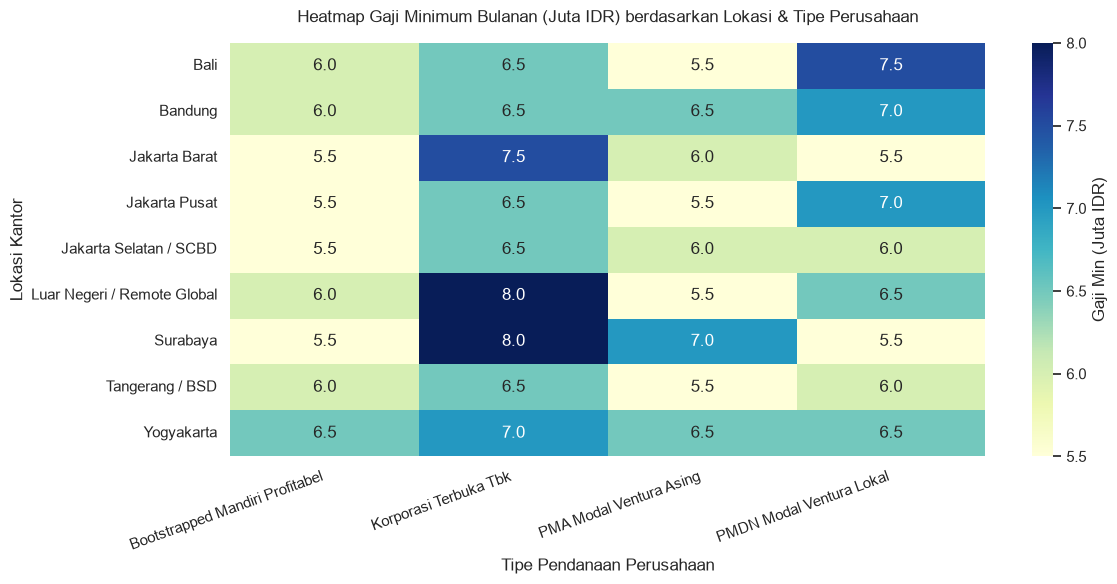

In [3]:
plt.figure(figsize=(12, 6))

# Buat Pivot Table (Gaji Minimum dalam Juta IDR)
pivot_min_salary = df.pivot_table(
    index='lokasi_kantor', 
    columns='tipe_pendanaan', 
    values='gaji_pokok_bulanan_idr', 
    aggfunc='min'
) / 1e6

sns.heatmap(pivot_min_salary, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Gaji Min (Juta IDR)'})
plt.title('Heatmap Gaji Minimum Bulanan (Juta IDR) berdasarkan Lokasi & Tipe Perusahaan', fontsize=12, pad=15)
plt.xlabel('Tipe Pendanaan Perusahaan')
plt.ylabel('Lokasi Kantor')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()